# Execution and realisation

Did the simulator run what was specified, is a run repeatable, and is the environment recorded?

The live cells are small and take a few minutes on a laptop CPU. Campaign-scale numbers are read from `results/v2/summary.json`. Everything here measures injected noise in one simple simulator setup, so none of it says anything about a real vehicle.

**Matching assessment**

- [Execution and realisation](https://niharvaghela1995.github.io/masters-thesis/assessments/s05_execution_realisation.html)

In [1]:
import json, sys, tempfile, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from stp import runner, scenario as S
from stp.v2.config import CANDIDATES, LEVELS, cfg_for
from stp.v2 import rules as RL
SPACE = CANDIDATES["A"]
SUMMARY = json.load(open(ROOT / "results/v2/summary.json"))
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
BLUE, ORANGE = "#2a78d6", "#eb6834"
def along(speeds, k1=0.012, k2=-0.004, gust=0.8):
    return [S.Params(float(v), k1, k2, gust) for v in speeds]
def reruns(p, n, level="medium", base=0):
    return [runner.run(p, base + i, LEVELS[level]) for i in range(n)]


## S05-P01: a run may not realise the intended scenario

Each seeded defect executes something other than the specification. The realisation check must say so, and the run then gets no verdict.

In [2]:
CLEAN = S.Params(15.0, 0.01, -0.01, 0.0)
print("clean run gates:", runner.run(CLEAN, 1)["gates"])
defects = {"mirrored road": S.Params(15.0, -0.01, -0.01, 0.0), "wrong second arc": S.Params(15.0, 0.01, 0.03, 0.0), "speed not applied": S.Params(20.0, 0.01, -0.01, 0.0)}
for name, executed in defects.items():
    r = runner.run(executed, 1, spec=CLEAN)
    print(f"{name:20s} realised={r['realised']} failed gates={[g for g, ok in r['gates'].items() if not ok]}")
r = runner.run(CLEAN, 1, external=False)
print(f"{'controller not in loop':20s} realised={r['realised']} failed gates={[g for g, ok in r['gates'].items() if not ok]}")

clean run gates: {'loaded': True, 'external_control': True, 'start_pose': True, 'speed_applied': True, 'road_arc1': True, 'road_arc2': True, 'clock': True, 'reached_curve': True}
mirrored road        realised=False failed gates=['road_arc1']
wrong second arc     realised=False failed gates=['road_arc2']
speed not applied    realised=False failed gates=['speed_applied']


controller not in loop realised=False failed gates=['external_control']


## S05-P02: identical inputs, identical runs?

Here the simulator is deterministic given the seed, so all run-to-run variation is the injected randomness. On a real stack this separation is not available.

In [3]:
p = S.Params(20.0, 0.014, -0.004, 0.8)
same = [runner.run(p, 7, LEVELS["medium"])["margin"] for _ in range(5)]
other = [r["margin"] for r in reruns(p, 30, "medium", 100)]
print("same seed, five runs:", set(np.round(same, 9)))
print(f"fresh seeds: mean margin {np.mean(other):.3f}, sd {np.std(other):.3f}, failed {np.mean([m < 0 for m in other]):.2f}")

same seed, five runs: {-0.214905679}
fresh seeds: mean margin -0.094, sd 0.257, failed 0.70


## S04-P05: latency as a hidden cause of failure

The first campaign's failures were decided by the latency drawn for each run. The live sweep repeats the check with gust 0, so latency acts alone, on low-demand scenarios.

failed share by latency, ms (live, 20 scenarios): {100: 0.0, 200: 0.0, 300: 0.0, 400: 0.35, 460: 1.0}
saved gate, failures of 100: {'low': {'100': 0, '200': 0, '300': 0, '360': 0, '400': 0, '460': 87}, 'medium': {'100': 0, '200': 0, '300': 0, '360': 0, '400': 0, '460': 90}, 'high': {'100': 0, '200': 0, '300': 0, '360': 0, '400': 28, '460': 98}}


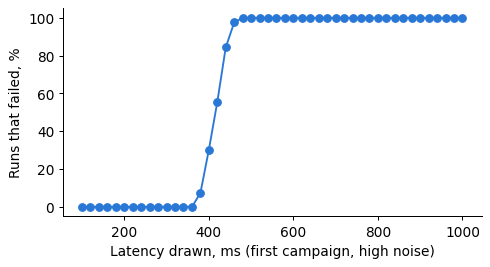

In [4]:
g = np.random.default_rng(5); X = g.uniform(SPACE["xl"], SPACE["xu"], (4000, 4)); X = X[X[:, 0] ** 2 * np.maximum(X[:, 1], np.abs(X[:, 2])) <= 3][:20]; X[:, 3] = 0
sw = {}
for steps in (5, 10, 15, 20, 23):
    c = cfg_for(f"high@{steps}"); sw[steps * 20] = np.mean([runner.run(S.Params(*map(float, x)), i, c)["failed"] for i, x in enumerate(X)])
print("failed share by latency, ms (live, 20 scenarios):", sw)
A = SUMMARY["gate"]["candidates"]["A"]["G0_amended"]
print("saved gate, failures of 100:", {l: {ms: x["failed"] for ms, x in v.items()} for l, v in A.items()})
D = json.load(open(ROOT / "results/diagnostics.json"))["high"]["by_latency"]
x = sorted(map(int, D)); plt.figure(figsize=(6, 3)); plt.plot([k * 20 for k in x], [100 * D[str(k)]["fail_rate"] for k in x], "o-", color=BLUE); plt.xlabel("Latency drawn, ms (first campaign, high noise)"); plt.ylabel("Runs that failed, %"); plt.show()

## S05-P05: harness faults must not corrupt a campaign

Batches checkpoint their results and a restart runs only what is missing. This simulates a crash with a half-written last line.

In [5]:
from stp.v2.jobs import read_jsonl, run_jobs
d = Path(tempfile.mkdtemp()); f = d / "demo.jsonl"
jobs = [("medium", S.Params(15.0, 0.01, -0.01, 0.2).dict(), i, 0, "demo") for i in range(40)]
run_jobs(d, "first", jobs[:25], f, workers=2)
with open(f, "a") as o: o.write('[99, 0, tr')
run_jobs(d, "resume", jobs, f, workers=2)
rows = read_jsonl(f); print("rows:", len(rows), "unique ids:", len({r[0] for r in rows}))

2026-11-10 13:25:12 first total 25 done 0 to run 25


2026-11-10 13:25:14 first finished 25 2 s


2026-11-10 13:25:14 resume total 40 done 25 to run 15


2026-11-10 13:25:15 resume finished 15 1 s


rows: 40 unique ids: 40


## S05-P06: is the environment recorded?

Each campaign saves its code commit, versions and hashes.

In [6]:
P = SUMMARY["provenance"]; print({k: P[k] for k in ("code_commit", "code_dirty", "python", "dt", "frozen")})
print((ROOT / "env/esmini.lock").read_text()); print((ROOT / "env/opensbt.lock").read_text())

{'code_commit': 'a9aaccd04c08f9cdaf56674e18a24f0d55aed11d', 'code_dirty': False, 'python': '3.10.12', 'dt': 0.02, 'frozen': 'A'}
version=v3.11.0
git_rev=v3.11.0-0-6ce66361
url=https://github.com/esmini/esmini/releases/download/v3.11.0/esmini-bin_Linux.zip
sha256=3c5b546f109356a1c5e7ab4351baf5be4daa6170a5518b3da29a6c3653d591a2

repo=https://github.com/opensbt/opensbt-core.git
tag=0.1.7
commit=3ace1864802f49e524d9612642bc6feb9d1f0caf

